### HUGO CABAÑA
## Hice este ejemplo y pude realizarlo.

# 🎨 De ruido a imagen — Generación de imágenes con IA
### Módulo 2: Deep Learning · Diplomatura en IA · UTN 2026

---

**La idea central de esta clase:**
Stable Diffusion convierte ruido aleatorio en una imagen, guiado por tu descripción de texto. Hoy vas a:

1. Cargar Stable Diffusion en Colab (gratis, con GPU)
2. Generar tu primera imagen con un prompt simple
3. **Ver el proceso paso a paso** — el ruido convirtiéndose en imagen
4. Experimentar con `guidance_scale` — cuánto "obedece" el modelo a tu texto
5. Comparar un prompt simple vs uno detallado
6. Crear una galería grupal con los prompts de toda la clase

> ⚠️ **IMPORTANTE — Activar GPU:**
> Arriba a la derecha → `Entorno de ejecución` → `Cambiar tipo de entorno de ejecución` → Acelerador de hardware: **T4 GPU**
>
> Sin GPU, cada imagen puede tardar 5-10 minutos en vez de ~15 segundos.

---

In [4]:
# ─── INSTALACIÓN ─────────────────────────────────────────────────────
# La librería 'diffusers' de HuggingFace tiene todo lo necesario
!pip install -q diffusers transformers accelerate safetensors

import torch
from diffusers import StableDiffusionPipeline, DPMSolverMultistepScheduler
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

print('✅ Librerías instaladas')

# Verificar GPU
if torch.cuda.is_available():
    print(f'✅ GPU disponible: {torch.cuda.get_device_name(0)}')
    device = 'cuda'
    dtype  = torch.float16
else:
    print('⚠️  Sin GPU — la generación será MUY lenta (5-10 min por imagen)')
    print('   Activá GPU: Entorno de ejecución → Cambiar tipo → T4 GPU')
    device = 'cpu'
    dtype  = torch.float32

✅ Librerías instaladas
✅ GPU disponible: Tesla T4


---
## Parte 1 — Cargar Stable Diffusion

Vamos a usar **Stable Diffusion v1.5**, un modelo open source de Stability AI entrenado con cientos de millones de pares imagen-texto.

La primera vez descarga ~4GB — tarda 1-2 minutos. Las siguientes veces es instantáneo (queda en caché).

In [5]:
# ─── CARGAR EL MODELO ────────────────────────────────────────────────
print('Descargando Stable Diffusion v1.5... (puede tardar 1-2 min la primera vez)')

pipe = StableDiffusionPipeline.from_pretrained(
    'runwayml/stable-diffusion-v1-5',
    torch_dtype=dtype,
    safety_checker=None,   # desactivamos el filtro NSFW para acelerar (uso educativo)
)

# Scheduler más rápido (menos pasos para el mismo resultado)
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe = pipe.to(device)

if device == 'cuda':
    pipe.enable_attention_slicing()  # reduce uso de memoria

print('\n✅ Stable Diffusion v1.5 cargado y listo')
print(f'   Dispositivo: {device}')
print(f'   Parámetros del modelo: ~860M (U-Net) + ~123M (codificador de texto CLIP)')

Descargando Stable Diffusion v1.5... (puede tardar 1-2 min la primera vez)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .



✅ Stable Diffusion v1.5 cargado y listo
   Dispositivo: cuda
   Parámetros del modelo: ~860M (U-Net) + ~123M (codificador de texto CLIP)


---
## Parte 2 — Tu primera imagen

Escribí un prompt simple y generá tu primera imagen. La primera ejecución tarda un poco más (compilación de kernels CUDA).

Generando: "un grupo de estudiantes en una clase de ia en videollamada"
Esto tarda ~15-20 segundos con GPU...



  0%|          | 0/25 [00:00<?, ?it/s]

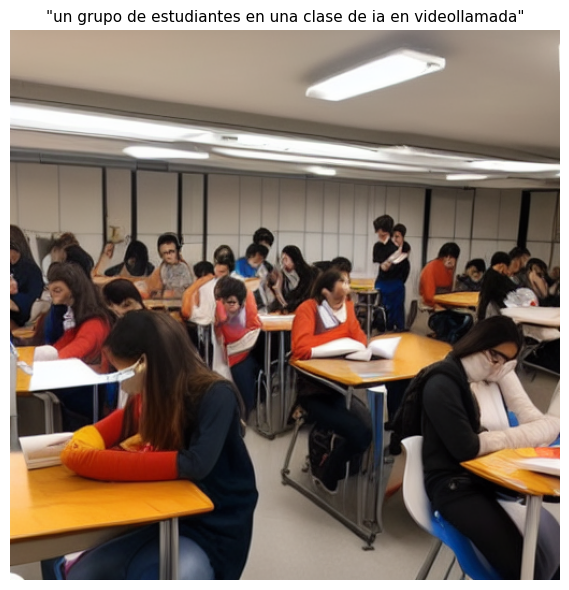

✅ ¡Listo! Esa imagen no existía hace 20 segundos.


In [14]:
# ─── TU PRIMER PROMPT ────────────────────────────────────────────────
# ✏️ Cambiá este texto por lo que quieras generar
# prompt = "a cat astronaut floating in space, watercolor style"
# prompt = "un auto en una ruta en el desierto estilo vintage"
prompt = "un grupo de estudiantes en una clase de ia en videollamada"

print(f'Generando: "{prompt}"')
print('Esto tarda ~15-20 segundos con GPU...\n')

# Semilla fija para reproducibilidad (mismo resultado cada vez que corras esta celda)
generator = torch.Generator(device=device).manual_seed(42)

imagen = pipe(
    prompt,
    num_inference_steps=25,   # cantidad de pasos de "limpieza"
    guidance_scale=7.5,       # cuánto "obedece" al prompt (valor típico)
    generator=generator,
).images[0]

plt.figure(figsize=(6, 6))
plt.imshow(imagen)
plt.axis('off')
plt.title(f'"{prompt}"', fontsize=11, wrap=True)
plt.tight_layout()
plt.show()

print('✅ ¡Listo! Esa imagen no existía hace 20 segundos.')

---
## Parte 3 — Ver el proceso paso a paso 🔥

Esta es la parte más importante de la clase. Vamos a **interceptar el proceso de difusión** y guardar una imagen en cada paso intermedio, para ver el ruido convirtiéndose en imagen frente a nuestros ojos.

In [17]:
# ─── CAPTURAR CADA PASO DEL PROCESO ─────────────────────────────────
# prompt_pasos = "a majestic lion with a golden mane, oil painting style"
prompt_pasos = "una cara de un extraterreste en Marte"
N_PASOS = 25

imagenes_intermedias = []

def callback_guardar_paso(pipe, step, timestep, callback_kwargs):
    """Se ejecuta en cada paso de difusión — decodifica y guarda la imagen actual"""
    latents = callback_kwargs['latents']
    # Decodificar el latente a imagen (solo para pasos que vamos a mostrar)
    with torch.no_grad():
        imagen_decodificada = pipe.vae.decode(
            latents / pipe.vae.config.scaling_factor, return_dict=False
        )[0]
    imagen_decodificada = pipe.image_processor.postprocess(imagen_decodificada, output_type='pil')[0]
    imagenes_intermedias.append((step, imagen_decodificada))
    return callback_kwargs

print(f'Generando "{prompt_pasos}" y guardando cada paso...')
print('Esto tarda un poco más porque decodificamos en cada paso (~40-60 seg)\n')

generator = torch.Generator(device=device).manual_seed(123)

resultado = pipe(
    prompt_pasos,
    num_inference_steps=N_PASOS,
    guidance_scale=7.5,
    generator=generator,
    callback_on_step_end=callback_guardar_paso,
    callback_on_step_end_tensor_inputs=['latents'],
)

print(f'✅ {len(imagenes_intermedias)} pasos capturados')

Generando "una cara de un extraterreste en Marte" y guardando cada paso...
Esto tarda un poco más porque decodificamos en cada paso (~40-60 seg)



  0%|          | 0/25 [00:00<?, ?it/s]

✅ 25 pasos capturados


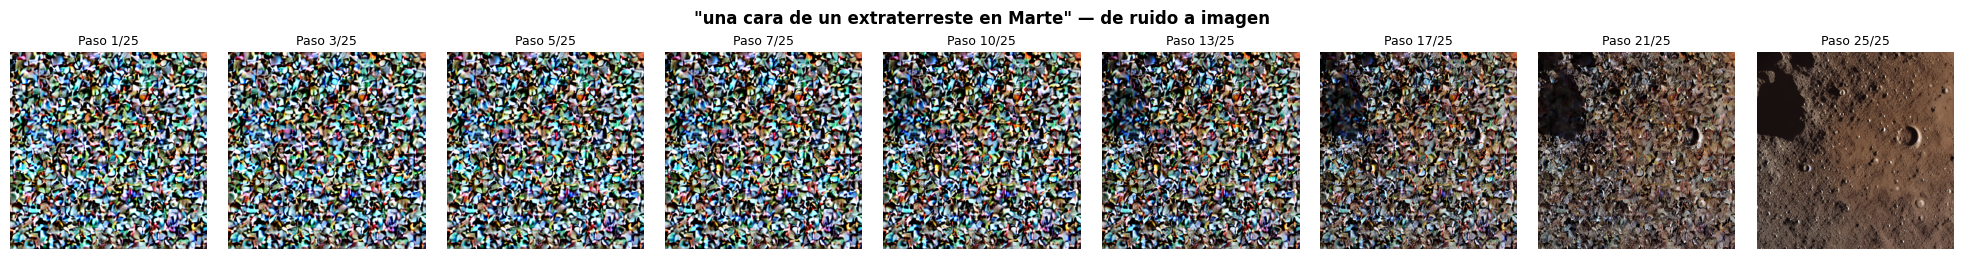

🔥 Así es como Stable Diffusion "esculpe" la imagen desde el ruido.
   Los primeros pasos definen formas generales (composición, colores grandes).
   Los últimos pasos refinan detalles (texturas, bordes, pequeños elementos).


In [18]:
# ─── VISUALIZAR LA PROGRESIÓN ────────────────────────────────────────
# Mostrar pasos seleccionados (no todos, para que se vea la progresión)
indices_a_mostrar = [0, 2, 4, 6, 9, 12, 16, 20, len(imagenes_intermedias)-1]
indices_a_mostrar = sorted(set([i for i in indices_a_mostrar if i < len(imagenes_intermedias)]))

n = len(indices_a_mostrar)
fig, axes = plt.subplots(1, n, figsize=(2.2*n, 2.6))
fig.suptitle(f'"{prompt_pasos}" — de ruido a imagen', fontsize=12, fontweight='bold')

for ax, idx in zip(axes, indices_a_mostrar):
    step_num, img = imagenes_intermedias[idx]
    ax.imshow(img)
    ax.set_title(f'Paso {step_num+1}/{N_PASOS}', fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.show()

print('🔥 Así es como Stable Diffusion "esculpe" la imagen desde el ruido.')
print('   Los primeros pasos definen formas generales (composición, colores grandes).')
print('   Los últimos pasos refinan detalles (texturas, bordes, pequeños elementos).')

---
## Parte 4 — Guidance Scale: ¿cuánto "obedece" al texto?

`guidance_scale` controla cuánto el modelo prioriza tu prompt vs. su "creatividad libre":

- **Bajo (1-3):** el modelo casi ignora el prompt, genera algo "libre" pero coherente como imagen
- **Medio (7-8):** balance entre seguir el prompt y mantener calidad — el valor más usado
- **Alto (15-20):** el modelo sigue el prompt al extremo, a veces sacrificando coherencia visual

Generando con guidance_scale=1...


  0%|          | 0/20 [00:00<?, ?it/s]

Generando con guidance_scale=4...


  0%|          | 0/20 [00:00<?, ?it/s]

Generando con guidance_scale=7.5...


  0%|          | 0/20 [00:00<?, ?it/s]

Generando con guidance_scale=15...


  0%|          | 0/20 [00:00<?, ?it/s]

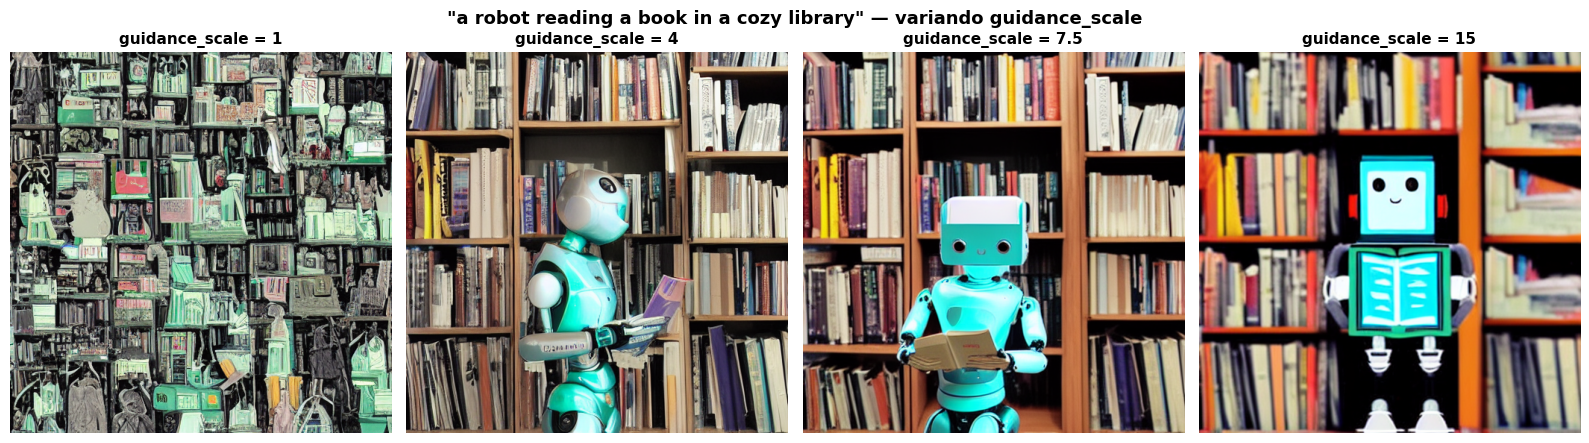


✅ Comparación lista
💡 Con guidance_scale muy alto, a veces aparecen artefactos o colores quemados —
   el modelo "fuerza" tanto seguir el texto que sacrifica realismo.


In [19]:
# ─── COMPARAR GUIDANCE SCALES ────────────────────────────────────────
prompt_guidance = "a robot reading a book in a cozy library"
guidance_values = [1, 4, 7.5, 15]

fig, axes = plt.subplots(1, len(guidance_values), figsize=(4*len(guidance_values), 4.5))
fig.suptitle(f'"{prompt_guidance}" — variando guidance_scale', fontsize=13, fontweight='bold')

for ax, gs in zip(axes, guidance_values):
    print(f'Generando con guidance_scale={gs}...')
    generator = torch.Generator(device=device).manual_seed(7)
    img = pipe(
        prompt_guidance,
        num_inference_steps=20,
        guidance_scale=gs,
        generator=generator,
    ).images[0]
    ax.imshow(img)
    ax.set_title(f'guidance_scale = {gs}', fontsize=11, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()

print('\n✅ Comparación lista')
print('💡 Con guidance_scale muy alto, a veces aparecen artefactos o colores quemados —')
print('   el modelo "fuerza" tanto seguir el texto que sacrifica realismo.')

---
## Parte 5 — Prompt simple vs. prompt detallado

Misma idea, mismo `seed` (semilla aleatoria) — solo cambia el nivel de detalle del texto.

Generando "Simple"...


  0%|          | 0/25 [00:00<?, ?it/s]

Generando "Detallado"...


  0%|          | 0/25 [00:00<?, ?it/s]

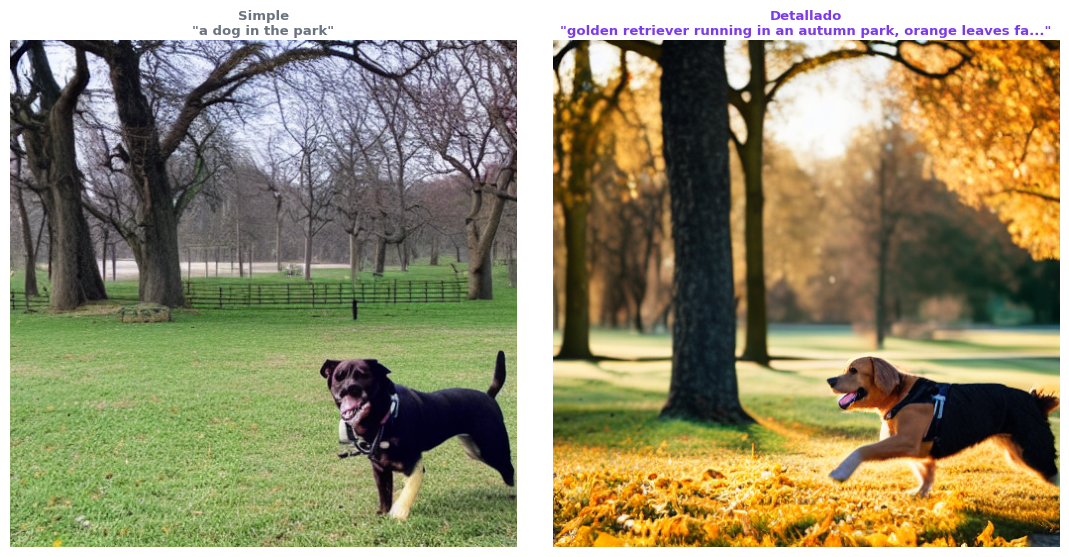


💡 Misma semilla, mismo concepto base — pero el nivel de detalle del prompt
   cambia radicalmente la composición, iluminación y estilo del resultado.


In [20]:
# ─── PROMPT SIMPLE VS DETALLADO ──────────────────────────────────────
prompts_comparar = {
    "Simple":    "a dog in the park",
    "Detallado": (
        "golden retriever running in an autumn park, orange leaves falling, "
        "golden hour sunlight, professional photography, 85mm lens, "
        "shallow depth of field, blurred background"
    ),
}

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))

for ax, (label, prompt_c) in zip(axes, prompts_comparar.items()):
    print(f'Generando "{label}"...')
    generator = torch.Generator(device=device).manual_seed(99)
    img = pipe(
        prompt_c,
        num_inference_steps=25,
        guidance_scale=7.5,
        generator=generator,
    ).images[0]
    ax.imshow(img)
    color = '#6B7280' if label == 'Simple' else '#7C3AED'
    ax.set_title(f'{label}\n"{prompt_c[:60]}{"..." if len(prompt_c)>60 else ""}"',
                  fontsize=9.5, color=color, fontweight='bold', wrap=True)
    ax.axis('off')

plt.tight_layout()
plt.show()

print('\n💡 Misma semilla, mismo concepto base — pero el nivel de detalle del prompt')
print('   cambia radicalmente la composición, iluminación y estilo del resultado.')

---
## Parte 6 — Galería grupal 🎨

Cada alumno escribe su propio prompt. Vamos generando uno por uno y armamos una galería con todos los resultados de la clase.

In [21]:
# ─── GALERÍA GRUPAL ──────────────────────────────────────────────────
# Cada alumno agrega su prompt y nombre a esta lista
# Formato: ("nombre del alumno", "prompt en inglés")

galeria_prompts = [
    ("Ejemplo 1", "a steampunk treehouse in a misty forest, highly detailed"),
    ("Ejemplo 2", "a futuristic city street at night, neon signs, rain, cyberpunk style"),
    ("Ejemplo 3", "a cozy bookstore cafe with warm lighting, autumn, watercolor"),
    # ✏️ Agregá más líneas acá: ("Nombre", "tu prompt"),
    ("Ruben", "una foto del equipo que va a ganar el mundial"),
    ("Alan", "A colossal blue whale swimming gracefully through the flooded streets of a Victorian city, towering gothic buildings partially submerged in crystal clear water, ornate iron balconies covered with moss and vines, old gas lamps glowing beneath the water surface, citizens watching from rooftops and upper windows in amazement, schools of colorful fish swimming between abandoned horse carriages, dramatic cinematic lighting, golden sunset reflecting on the water, volumetric light rays piercing through mist, ultra detailed architecture, realistic water reflections and ripples, surreal realism, photorealistic textures, atmospheric perspective, breathtaking composition, masterpiece, highly detailed, 8k, professional photography, sharp focus"),
    ("Federico", "Un extraterrestre caminando por el paisaje marciano")

]

print(f'{len(galeria_prompts)} prompts en la galería')
for nombre, p in galeria_prompts:
    print(f'  {nombre}: "{p}"')

6 prompts en la galería
  Ejemplo 1: "a steampunk treehouse in a misty forest, highly detailed"
  Ejemplo 2: "a futuristic city street at night, neon signs, rain, cyberpunk style"
  Ejemplo 3: "a cozy bookstore cafe with warm lighting, autumn, watercolor"
  Ruben: "una foto del equipo que va a ganar el mundial"
  Alan: "A colossal blue whale swimming gracefully through the flooded streets of a Victorian city, towering gothic buildings partially submerged in crystal clear water, ornate iron balconies covered with moss and vines, old gas lamps glowing beneath the water surface, citizens watching from rooftops and upper windows in amazement, schools of colorful fish swimming between abandoned horse carriages, dramatic cinematic lighting, golden sunset reflecting on the water, volumetric light rays piercing through mist, ultra detailed architecture, realistic water reflections and ripples, surreal realism, photorealistic textures, atmospheric perspective, breathtaking composition, masterpi

[1/6] Generando para Ejemplo 1: "a steampunk treehouse in a misty forest, highly de..."


  0%|          | 0/22 [00:00<?, ?it/s]

[2/6] Generando para Ejemplo 2: "a futuristic city street at night, neon signs, rai..."


  0%|          | 0/22 [00:00<?, ?it/s]

[3/6] Generando para Ejemplo 3: "a cozy bookstore cafe with warm lighting, autumn, ..."


  0%|          | 0/22 [00:00<?, ?it/s]

... (3 outputs left out)

[5/6] Generando para Alan: "A colossal blue whale swimming gracefully through ..."


  0%|          | 0/22 [00:00<?, ?it/s]

[6/6] Generando para Federico: "Un extraterrestre caminando por el paisaje marcian..."


  0%|          | 0/22 [00:00<?, ?it/s]

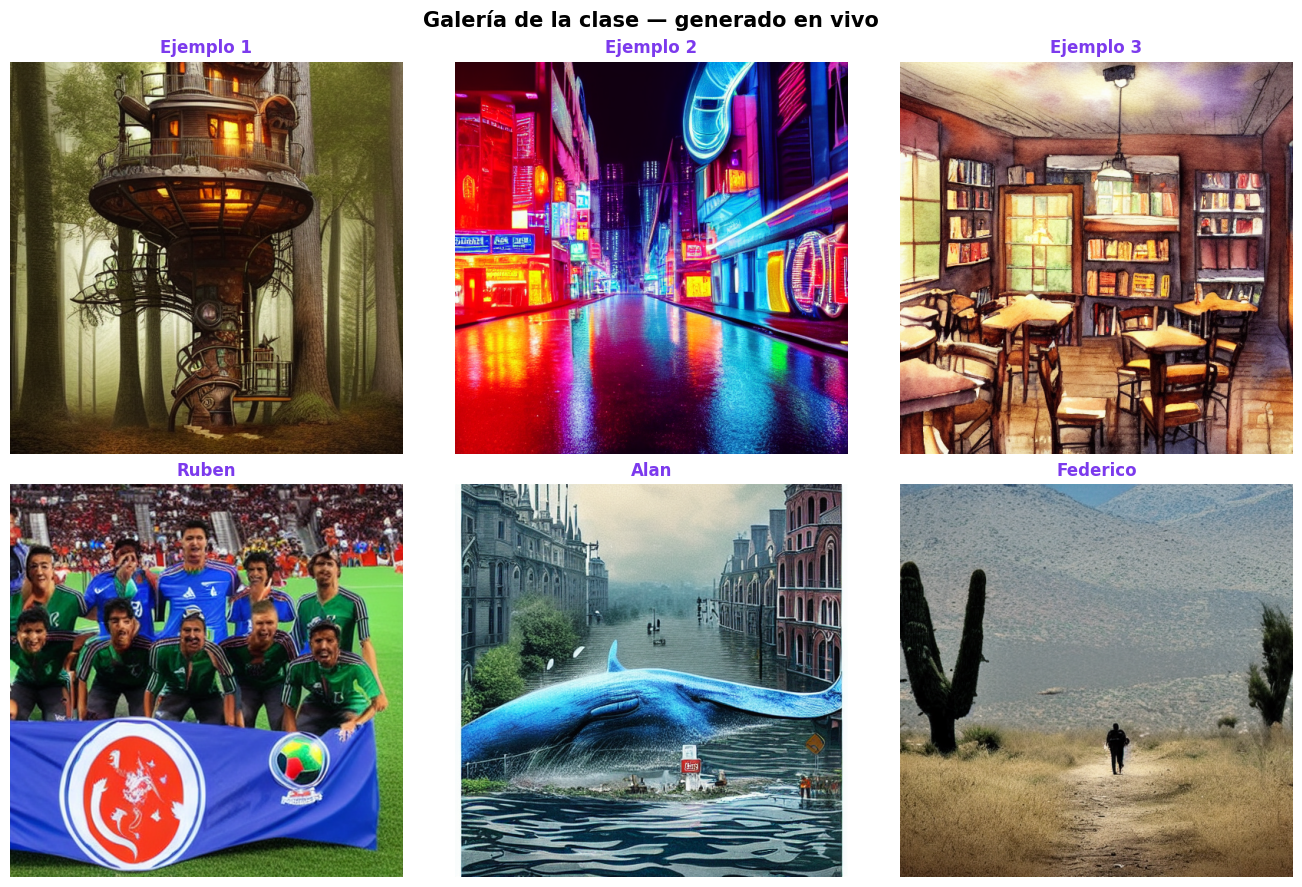


✅ Galería completa — todas estas imágenes se generaron en esta clase, en vivo.


In [22]:
# ─── GENERAR LA GALERÍA ──────────────────────────────────────────────
n = len(galeria_prompts)
cols = min(3, n)
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(4.5*cols, 4.5*rows))
fig.suptitle('Galería de la clase — generado en vivo', fontsize=15, fontweight='bold')

if rows == 1:
    axes = [axes] if cols == 1 else axes
else:
    axes = axes.flatten()

for i, (nombre, prompt_g) in enumerate(galeria_prompts):
    print(f'[{i+1}/{n}] Generando para {nombre}: "{prompt_g[:50]}..."')
    generator = torch.Generator(device=device).manual_seed(2024 + i)
    img = pipe(
        prompt_g,
        num_inference_steps=22,
        guidance_scale=7.5,
        generator=generator,
    ).images[0]

    ax = axes[i]
    ax.imshow(img)
    ax.set_title(nombre, fontsize=12, fontweight='bold', color='#7C3AED')
    ax.axis('off')

# Ocultar ejes vacíos si la grilla no se completa
for j in range(n, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

print('\n✅ Galería completa — todas estas imágenes se generaron en esta clase, en vivo.')

---
## Resumen de lo que aprendiste hoy

| Concepto | En una oración |
|----------|----------------|
| **Difusión** | Proceso de quitar ruido paso a paso, guiado por texto, hasta obtener una imagen |
| **Pasos de inferencia** | Cuántas veces se repite el proceso de "limpieza" — más pasos = más detalle (hasta un límite) |
| **Guidance scale** | Cuánto el modelo prioriza seguir tu prompt vs. su libertad creativa |
| **Codificador de texto (CLIP)** | Convierte tu prompt en un vector numérico que guía cada paso |
| **Prompt engineering** | El nivel de detalle del prompt cambia radicalmente el resultado |
| **Seed (semilla)** | Fijarla permite reproducir el mismo resultado — útil para comparar variantes |

### Para seguir explorando
- Probá otros modelos: `stabilityai/stable-diffusion-2-1`, `stabilityai/sdxl-turbo`
- Experimentá con `negative_prompt` para indicar qué NO querés ver
- Investigá `img2img` — usar una imagen propia como punto de partida en vez de ruido puro

---